# เล่นกับกล้องจำลอง (ท้ายวันที่ 1)
กล้องจำลองของ Basler ทำบางอย่างได้**เหมือนกล้องจริง** และบางอย่าง**ไม่ได้** ชุดนี้ให้ลองทั้งสองแบบ

| ลอง | เรื่อง | กล้องจำลองทำได้จริงไหม |
|---|---|---|
| 1 | ตัดภาพ (AOI) | ได้ เหมือนกล้องจริง |
| 2 | Pixel Format ขาวดำ / สี | ได้ เหมือนกล้องจริง |
| 3 | สายการผลิตจำลอง + Trigger | ได้ เหมือนกล้องจริง |
| 4 | Exposure, Gain, แสง, ชิ้นงานเคลื่อนที่ | **ไม่ได้** เราจึงจำลองผลด้วยโค้ดแทน |

กด **Shift + Enter** ทีละ cell

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../scripts"))

import cv2, time
import numpy as np
from ipywidgets import interact
from vision_camera import show, grab_emu, EmuLine, simulate_real, img_path
print("พร้อมใช้งาน")

พร้อมใช้งาน


In [2]:
def count_red(img, h_low=0, h_high=10, s_min=50, v_min=50, min_area=1000):
    """นับชิ้นสีแดงที่ใหญ่กว่า min_area และวาดกรอบ"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([h_low, s_min, v_min]), np.array([h_high, 255, 255]))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    out = img.copy()
    n = 0
    for c in contours:
        if cv2.contourArea(c) > min_area:
            x, y, w, h = cv2.boundingRect(c)
            cv2.rectangle(out, (x, y), (x + w, y + h), (200, 0, 100), 3)
            n += 1
    return n, out

In [11]:
def count_yellow(img, h_low=20, h_high=35, s_min=100, v_min=100, min_area=1000):
    """นับชิ้นสีเหลืองที่ใหญ่กว่า min_area และวาดกรอบ"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    
    # ช่วงสีเหลืองในระบบ HSV ของ OpenCV ปกติจะอยู่ประมาณ Hue: 20-35 
    mask = cv2.inRange(hsv, np.array([h_low, s_min, v_min]), np.array([h_high, 255, 255]))
    
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    out = img.copy()
    n = 0
    for c in contours:
        if cv2.contourArea(c) > min_area:
            x, y, w, h = cv2.boundingRect(c)
            # เปลี่ยนสีกรอบเป็นสีเหลืองด้วยระบบ BGR: (0, 255, 255)
            cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 255), 3)
            n += 1
    return n, out


## ลองที่ 1: ตัดภาพ (AOI = Area of Interest)
กล้องจริงตัดภาพได้ตั้งแต่ในตัวกล้อง เหลือเฉพาะส่วนที่สนใจ **ภาพเล็กลง = ส่งข้อมูลน้อยลง = ถ่ายได้เร็วขึ้น (fps สูงขึ้น)**
เลื่อนแถบ Width, Height, Offset แล้วดูว่าภาพที่ได้จากกล้องเปลี่ยนไปอย่างไร

In [4]:
def try_aoi(width=640, height=480, offset_x=0, offset_y=0):
    frame = grab_emu("shapes.png", width=width, height=height,offset_x=offset_x, offset_y=offset_y)
    n, out = count_red(frame)
    h, w = frame.shape[:2]
    print(f"ภาพจากกล้อง {w} x {h} = {w*h:,} พิกเซล  ({w*h/307200*100:.0f}% ของภาพเต็ม)   นับแดงได้ {n} ชิ้น")
    show(out, titles=[f"AOI {w} x {h}"])

interact(try_aoi, width=(64, 640, 32), height=(64, 480, 32),offset_x=(0, 576, 32), offset_y=(0, 416, 32));

interactive(children=(IntSlider(value=640, description='width', max=640, min=64, step=32), IntSlider(value=480…

**คำถาม:** ถ้ารู้ว่าชิ้นงานอยู่ครึ่งขวาของภาพเสมอ ควรตั้ง AOI อย่างไร? ได้ประโยชน์อะไร?

## ลองที่ 2: Pixel Format ขาวดำ vs สี
กล้องส่งภาพได้หลายแบบ ลองดูว่าแต่ละแบบนับวัตถุสีแดงได้ไหม

BGR8Packed   -> นับแดงได้ 5 ชิ้น


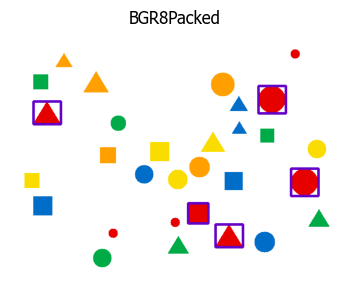

Mono8        -> นับแดงได้ 0 ชิ้น


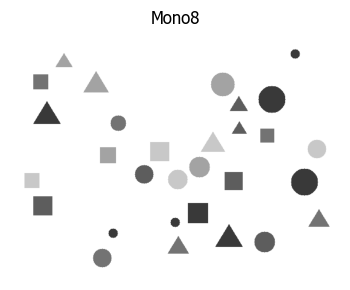

BayerRG8     -> นับแดงได้ 5 ชิ้น


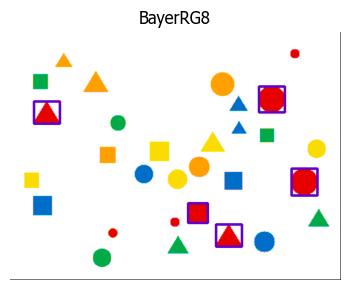

In [5]:
for pf in ["BGR8Packed", "Mono8", "BayerRG8"]:
    frame = grab_emu("shapes.png", pixel_format=pf)
    n, out = count_red(frame)
    print(f"{pf:12s} -> นับแดงได้ {n} ชิ้น")
    show(out, titles=[pf], size=4)

**สังเกต:**
- **Mono8** (ขาวดำ) นับได้ **0 ชิ้น** เพราะไม่มีข้อมูลสี ค่า S เป็น 0 ทั้งภาพ  งานที่ต้องแยกสีต้องใช้กล้องสี
- **BayerRG8** คือข้อมูลดิบจากเซนเซอร์สีที่ต้องแปลงก่อน ขอบวัตถุอาจมีสีเพี้ยนเล็กน้อย
- กล้องขาวดำมีข้อดี: ภาพคมกว่าและไวแสงกว่า เหมาะกับงานวัดขนาด อ่านตัวอักษร

## ลองที่ 3: สายการผลิตจำลอง
ใส่ภาพถาดไว้ในโฟลเดอร์ `images/line/` 6 ภาพ กล้องจำลองจะส่งภาพ**ทีละถาด ทุกครั้งที่สั่ง Trigger** เหมือนชิ้นงานเลื่อนมาถึงใต้กล้อง
งาน: **ทุกถาดต้องมีชิ้นแดงใหญ่ 5 ชิ้น**  ทายก่อนรันว่าจะมีกี่ถาดที่ NG

ถาดที่ 1: พบ 5 ชิ้น -> OK   (23 ms)


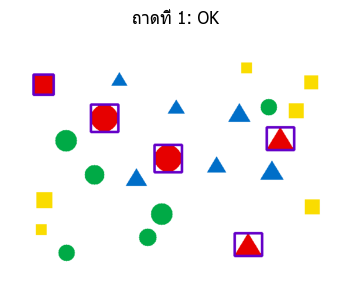

ถาดที่ 2: พบ 4 ชิ้น -> NG   (33 ms)


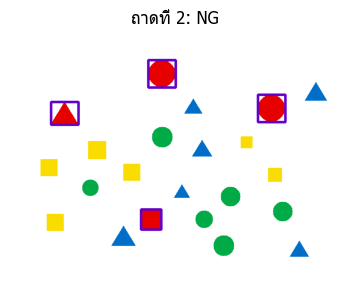

ถาดที่ 3: พบ 5 ชิ้น -> OK   (22 ms)


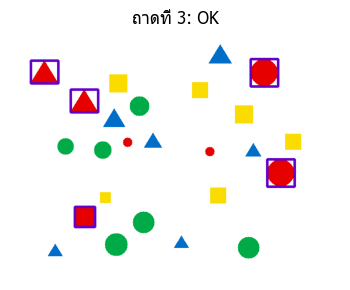

ถาดที่ 4: พบ 6 ชิ้น -> NG   (23 ms)


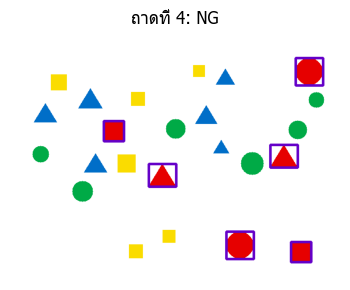

ถาดที่ 5: พบ 5 ชิ้น -> OK   (21 ms)


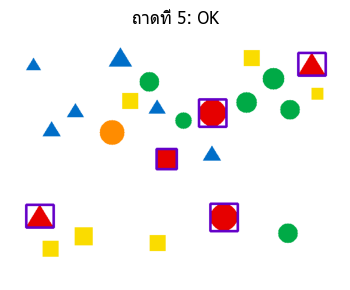

ถาดที่ 6: พบ 5 ชิ้น -> OK   (30 ms)


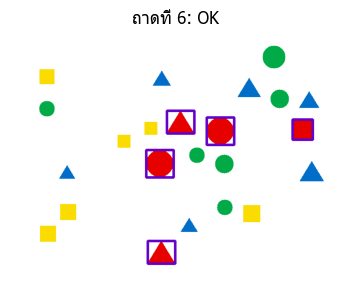

สรุป OK 4 ถาด   NG 2 ถาด


In [7]:
EXPECT = 5
line = EmuLine("line")                       # เปิดกล้องแบบรอ Trigger
try:
    results = []
    for i in range(6):
        t0 = time.perf_counter()
        frame = line.trigger()               # ชิ้นงานมาถึง -> ถ่าย 1 ภาพ
        n, out = count_red(frame)
        verdict = "OK" if n == EXPECT else "NG"
        ms = (time.perf_counter() - t0) * 1000
        results.append(verdict)
        print(f"ถาดที่ {i+1}: พบ {n} ชิ้น -> {verdict}   ({ms:.0f} ms)")
        show(out, titles=[f"ถาดที่ {i+1}: {verdict}"], size=4)
finally:
    line.close()                             # ปิดกล้องเสมอ
print(f"สรุป OK {results.count('OK')} ถาด   NG {results.count('NG')} ถาด")

**ลองเอง:**
1. ถาดที่ 3 มีชิ้นแดง**เล็ก**ปนมา 2 ชิ้น แต่ผลเป็น OK เพราะ `min_area` กรองทิ้ง  ในงานจริงควรเป็น OK หรือ NG?
2. ถาดที่ 5 มีชิ้น**สีส้ม**ปน ลองเปลี่ยน `h_high` ใน `count_red` เป็น 20 แล้วรันใหม่ ผลเปลี่ยนไหม? ทำไมการตั้งช่วงสีให้กว้างเกินไปจึงอันตราย

ถาดที่ 1: พบ 0 ชิ้น -> NG   (25 ms)


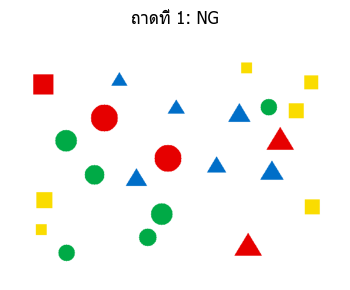

ถาดที่ 2: พบ 4 ชิ้น -> NG   (27 ms)


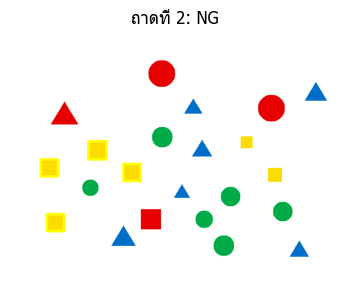

ถาดที่ 3: พบ 2 ชิ้น -> NG   (21 ms)


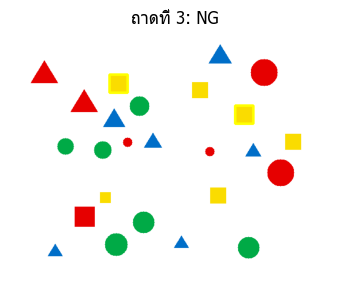

ถาดที่ 4: พบ 1 ชิ้น -> NG   (35 ms)


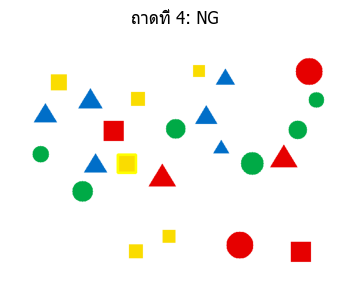

ถาดที่ 5: พบ 1 ชิ้น -> NG   (35 ms)


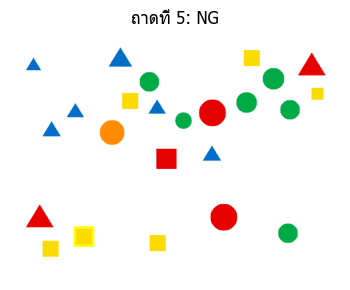

ถาดที่ 6: พบ 1 ชิ้น -> NG   (21 ms)


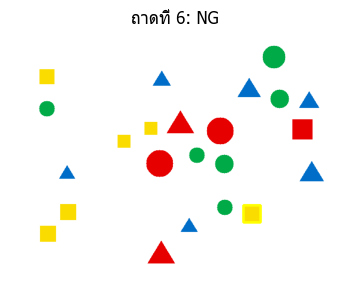

สรุป OK 0 ถาด   NG 6 ถาด


In [12]:
EXPECT = 5
line = EmuLine("line")                       # เปิดกล้องแบบรอ Trigger
try:
    results = []
    for i in range(6):
        t0 = time.perf_counter()
        frame = line.trigger()               # ชิ้นงานมาถึง -> ถ่าย 1 ภาพ
        n, out = count_yellow(frame)
        verdict = "OK" if n == EXPECT else "NG"
        ms = (time.perf_counter() - t0) * 1000
        results.append(verdict)
        print(f"ถาดที่ {i+1}: พบ {n} ชิ้น -> {verdict}   ({ms:.0f} ms)")
        show(out, titles=[f"ถาดที่ {i+1}: {verdict}"], size=4)
finally:
    line.close()                             # ปิดกล้องเสมอ
print(f"สรุป OK {results.count('OK')} ถาด   NG {results.count('NG')} ถาด")

## ลองที่ 4: ทำให้เหมือนกล้องจริง
กล้องจำลอง**รับค่า Exposure และ Gain ได้ แต่ภาพไม่เปลี่ยน** ส่วนนี้จึงใช้ฟังก์ชัน `simulate_real()` จำลองผลที่กล้องจริงจะเจอ

| แถบ | กล้องจริงจะเป็นอย่างไร |
|---|---|
| `exposure_ms` | มากขึ้น = สว่างขึ้น แต่ถ้าชิ้นงานเคลื่อนที่ ภาพจะเบลอ |
| `gain_db` | มากขึ้น = สว่างขึ้น แต่**จุดรบกวน**มากขึ้น |
| `light` | ไฟในห้องมืด/สว่าง |
| `speed` | ชิ้นงานเคลื่อนที่บนสายพาน |
| `s_min`, `v_min` | ค่าของโปรแกรมนับ ใช้**แก้**ให้กลับมานับถูก |

**ภารกิจ:**
1. **ห้องมืด:** ลด `light` เหลือ 0.2 นับได้กี่ชิ้น? (เฉลย: 0 ชิ้น)
2. **แก้ด้วยกล้อง:** เพิ่ม `exposure_ms` เป็น 15 หรือเพิ่ม `gain_db` เป็น 12 ให้กลับมานับได้ 5
3. **ชิ้นงานวิ่ง:** คืนค่า `light` = 1.0 ตั้ง `speed` = 2 และ `exposure_ms` = 10 ภาพเบลอ นับผิด
   แก้โดย**ลด** `exposure_ms` เหลือ 2 แล้วชดเชยความสว่างด้วย `gain_db` = 8  นี่คือเหตุผลที่ไลน์เร็วต้องใช้ Exposure สั้น
4. **Gain สูงเกิน:** ตั้ง `light` = 0.15 และ `gain_db` = 20 สังเกตจุดรบกวน แล้วลองแก้ด้วย `s_min`, `v_min`

In [8]:
base = grab_emu("shapes.png")

def try_real(exposure_ms=5.0, gain_db=0.0, light=1.0, speed=0.0, s_min=50, v_min=50):
    img = simulate_real(base, exposure_ms, gain_db, light, speed)
    n, out = count_red(img, s_min=s_min, v_min=v_min)
    verdict = "OK" if n == 5 else "NG"
    print(f"ความสว่างเฉลี่ย {img.mean():.0f}   นับแดงได้ {n} ชิ้น -> {verdict}")
    show(img, out, titles=["ภาพที่กล้องจริงน่าจะได้", f"ผลการนับ: {n} ({verdict})"])

interact(try_real, exposure_ms=(0.5, 20.0, 0.5), gain_db=(0.0, 24.0, 1.0),
         light=(0.1, 1.5, 0.1), speed=(0.0, 4.0, 0.5), s_min=(0, 255, 5), v_min=(0, 255, 5));

interactive(children=(FloatSlider(value=5.0, description='exposure_ms', max=20.0, min=0.5, step=0.5), FloatSli…

In [ ]:
base = grab_emu("shapes.png")

def try_real(exposure_ms=5.0, gain_db=0.0, light=1.0, speed=0.0, s_min=50, v_min=50):
    img = simulate_real(base, exposure_ms, gain_db, light, speed)
    n, out = count_yellow(img, s_min=s_min, v_min=v_min)
    verdict = "OK" if n == 5 else "NG"
    print(f"ความสว่างเฉลี่ย {img.mean():.0f}   นับแดงได้ {n} ชิ้น -> {verdict}")
    show(img, out, titles=["ภาพที่กล้องจริงน่าจะได้", f"ผลการนับ: {n} ({verdict})"])

interact(try_real, exposure_ms=(0.5, 20.0, 0.5), gain_db=(0.0, 24.0, 1.0),
         light=(0.1, 1.5, 0.1), speed=(0.0, 4.0, 0.5), s_min=(0, 255, 5), v_min=(0, 255, 5));

interactive(children=(FloatSlider(value=5.0, description='exposure_ms', max=20.0, min=0.5, step=0.5), FloatSli…

## สรุป: กล้องจำลอง vs กล้องจริง

| เรื่อง | กล้องจำลอง | กล้องจริง |
|---|---|---|
| ต่อกล้อง ตั้งค่า ถ่ายภาพด้วยโค้ด | ได้ | ได้ (โค้ดเดียวกัน) |
| AOI, Pixel Format, Trigger | ได้ | ได้ |
| Exposure, Gain เปลี่ยนความสว่าง | ไม่ได้ (ต้องจำลองด้วยโค้ด) | ได้ |
| จุดรบกวน ภาพเบลอ แสงเปลี่ยน | ไม่มี | มี ต้องจูนใหม่ |

**พรุ่งนี้:** เปลี่ยน `"emu"` เป็น `"basler"` แล้วจะเจอทุกอย่างในลองที่ 4 ของจริง